# Citi Bike rebalancing: the whole project, step by step

This notebook follows the report section by section. Each step says what we do and why, shows
the few lines of code that matter, and prints the number or the figure the report uses. It
reads what the pipeline scripts already saved in `data/processed/` and `figures/`, so it runs
in under a minute and never redoes the heavy work.

**The pipeline behind it**, in run order. Each script reads what the one before wrote.

| Step | Script | What it does | Time |
|---|---|---|---|
| 1 | `prepare_data.py` | Downloads two years of trips (92 million), fixes the station ids, counts starts and ends per station in 5-minute slots | 4 min |
| 2 | `station_days.py` | For every station and day: how far its stock fell and rose from its 04:00 level | 6 s |
| 3 | `explore.py` | Figures 1 to 5: when and where the flow runs one way, and whether it repeats | |
| 4 | `demand_model.py` | Regression of daily trips on weather and calendar, figures 6 and 7 | |
| 5 | `rebalance.py dev` / `test` | Replays every trip of a year under each schedule and counts riders turned away | 2-3 min |
| 6 | `rebalance_figures.py` | Figures 8 to 13 from the test run, and the check against Citi Bike's own reports | |

The shared logic (rebuilding stock, the target band, the budget, the replay) is in
`lib/rebalancing.py`; downloading is `lib/fetching.py`, map shapes `lib/geography.py`, chart
style `lib/chart_style.py`.

In [1]:
from datetime import date

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Image, display

from lib.rebalancing import HOLIDAYS, simulate_slots, target_band

PROCESSED = "data/processed"
stations = pl.read_parquet(f"{PROCESSED}/stations.parquet")
station_days = pl.read_parquet(f"{PROCESSED}/station_days.parquet")
summary = pl.read_parquet(f"{PROCESSED}/simulation-test-summary.parquet")

## 1. The business problem

Members ride from homes (Brooklyn, the East Village, the Upper West Side) to offices (Midtown,
Lower Manhattan) in the morning and back in the evening. Home stations run out of bikes, office
stations run out of docks, and the next rider is turned away. Citi Bike fixes this with trucks,
about 2,500 bikes a day. Every bike moved costs money, and a move in the wrong place prevents
nothing.

**Our question:** each night, which stations should be restocked or cleared, and by how many
bikes, to turn away the fewest riders per bike moved? And is a second visit during the day
worth it?

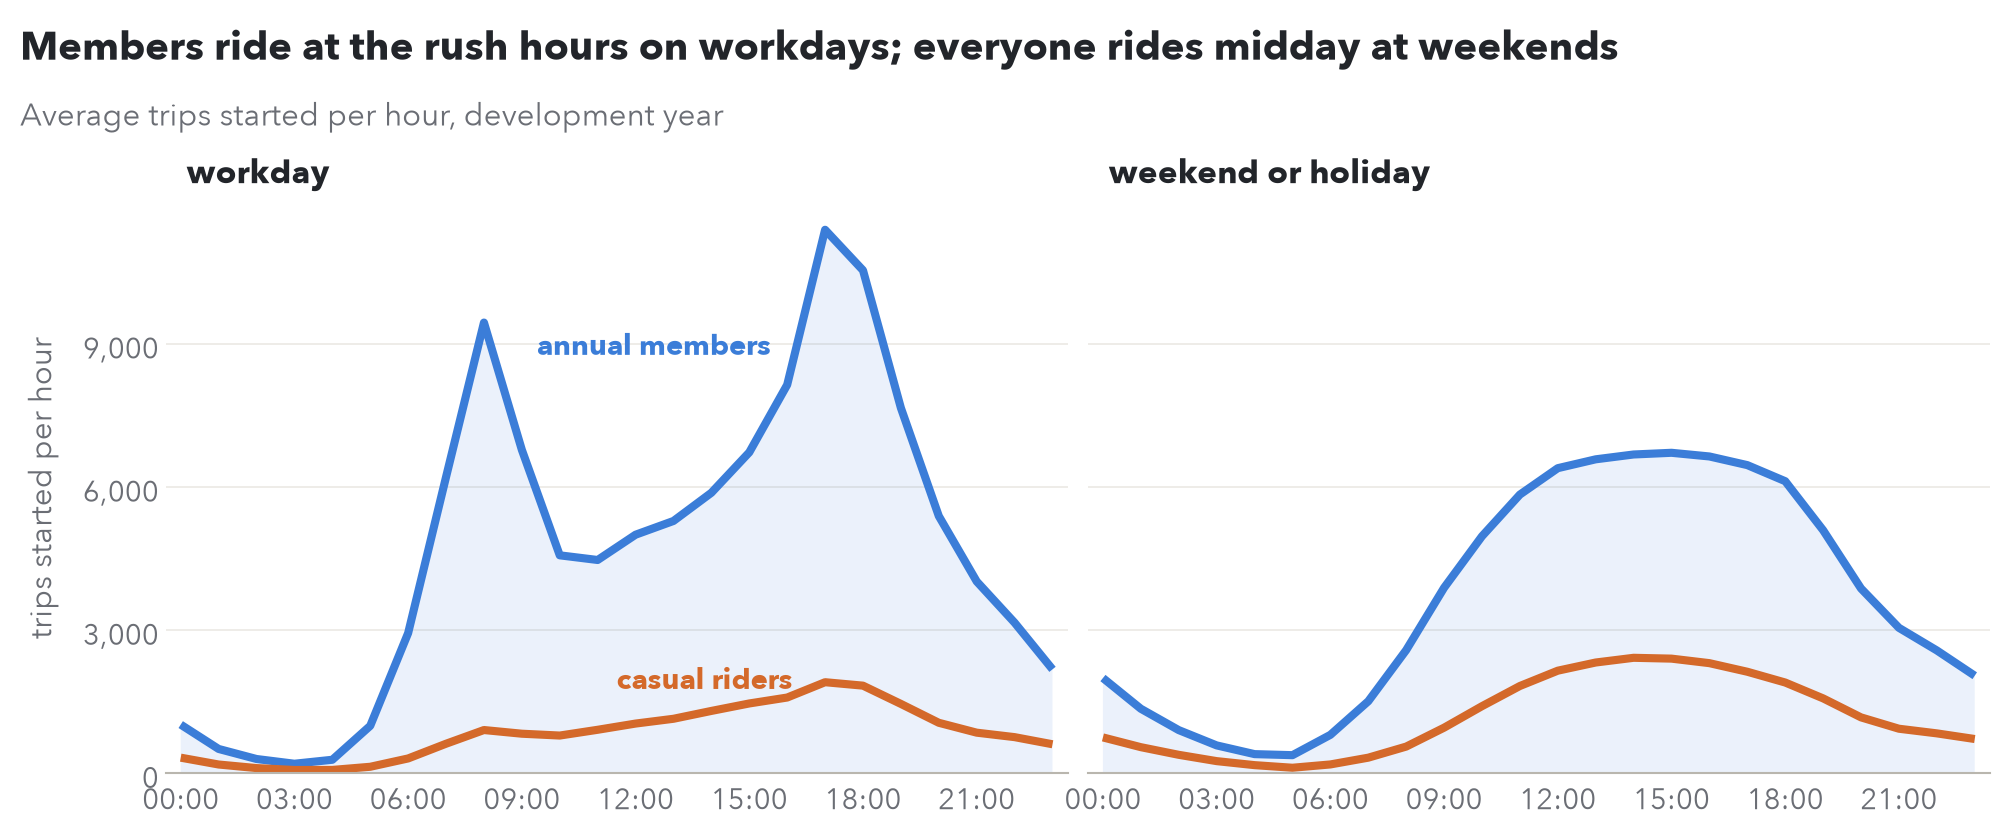

In [2]:
display(Image("figures/fig1-daily-rhythm.png", width=800))

Figure 1 is the whole problem in one picture: members spike at 08:00 and 17:00 on workdays,
casual riders do not. So every rule below treats workdays and weekends separately.

## 2. The trick: rebuilding every station's stock from public trips

Citi Bike publishes every trip (start and end station, start and end time) but never how many
bikes stand in a dock. We do not need that: a station's stock changes only when a bike leaves
or arrives. Count both in each 5-minute slot, add up arrivals minus departures, and you have
the station's stock relative to where it started at 04:00. We call that the **drift**.

`prepare_data.py` turned 92 million trips into those 5-minute counts. Here is one month's file:

In [3]:
bins = pl.read_parquet(f"{PROCESSED}/bins/202605.parquet")
print(f"{len(bins):,} rows, one per station and 5-minute slot with at least one trip")
bins.head(5)

4,723,146 rows, one per station and 5-minute slot with at least one trip


station_id,slot,starts,member_starts,ebike_starts,ends
str,datetime[μs],i16,i16,i16,i16
"""1964.01""",2026-05-01 16:15:00,2,0,2,0
"""1964.01""",2026-05-01 16:20:00,1,0,1,0
"""1964.01""",2026-05-01 18:30:00,0,0,0,1
"""1964.01""",2026-05-01 21:20:00,0,0,0,1
"""1964.01""",2026-05-02 12:50:00,0,0,0,1


A worked example: Broadway & W 25 St, an office station with 109 docks, on Tuesday 12 May 2026.
The drift is the running total of arrivals minus departures from 04:00.

Broadway & W 25 St: 109 docks
drift from 04:00: lowest 0, highest 105


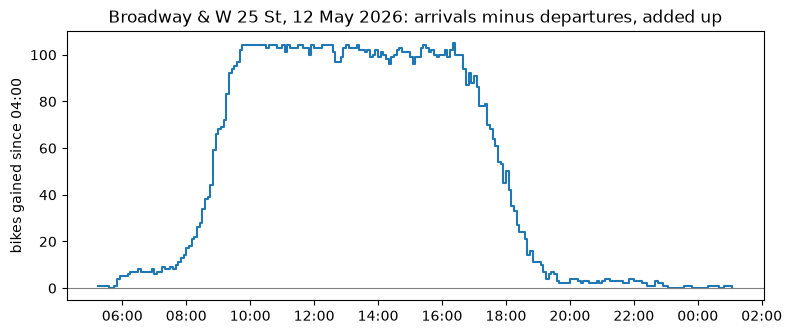

In [4]:
office = stations.filter(pl.col("name") == "Broadway & W 25 St").row(0, named=True)
day_slots = (
    bins.filter(
        pl.col("station_id") == office["station_id"],
        pl.col("slot").is_between(
            pl.datetime(2026, 5, 12, 4), pl.datetime(2026, 5, 13, 4), closed="left"
        ),
    )
    .sort("slot")
    .with_columns(drift=(pl.col("ends") - pl.col("starts")).cum_sum())
)
lowest, highest = day_slots["drift"].min(), day_slots["drift"].max()
print(f"{office['name']}: {office['capacity']} docks")
print(f"drift from 04:00: lowest {lowest}, highest {highest}")

fig, ax = plt.subplots(figsize=(9, 3.5))
_ = ax.step(day_slots["slot"], day_slots["drift"], where="post")
_ = ax.axhline(0, color="grey", lw=0.8)
_ = ax.set(
    ylabel="bikes gained since 04:00",
    title=f"{office['name']}, 12 May 2026: arrivals minus departures, added up",
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.show()

Read the chart as: starting from whatever it had at 04:00, the station gains about 105 bikes
by 10:00, holds them through the day, and gives them all back between 16:00 and 19:00. It
never drops below its 04:00 level. Two numbers decide whether a starting level
works that day:

- **need** = how far the drift falls below zero. Start with fewer bikes than that and the
  station runs empty at some point.
- **room** = docks minus how far the drift rises. Start with more bikes than that and the
  station fills up.

Any start between need and room carries the station through the whole day.

In [5]:
need = max(-lowest, 0)
room = office["capacity"] - max(highest, 0)
print(
    f"need {need}, room {room}: any start from {need} to {room} bikes works on this day"
)
print(f"half full would be {round(office['capacity'] / 2)} bikes")

need 0, room 4: any start from 0 to 4 bikes works on this day
half full would be 54 bikes


`station_days.py` stores the lowest and highest drift for every station and every day
(1.6 million station-days), which is everything the rules below use.

**The data's blind spots**, ranked by how much they could move the results:

1. Stock is never observed, only rebuilt. The simulation starts every station at the level a
   schedule sets at 04:00.
2. The real trips already include Citi Bike's own trucks. The simulation handles this: a rider
   turned away at an empty station never rides, so their bike never reaches the destination.
3. A rider who walked away from an empty station left no trip, so shortages are lower bounds.
   Every schedule faces the same trips, so the comparison holds.
4. Dock counts come from one day (22 Oct 2026); 81 stations without them are left out.
5. Within a 5-minute slot, departures go before arrivals.

The first year (Oct 2024 to Sep 2025) is for exploring and choosing every setting. The second
year (Oct 2025 to Sep 2026) is used once, at the end, to score the schedules.

## 3. When and where the flow runs one way

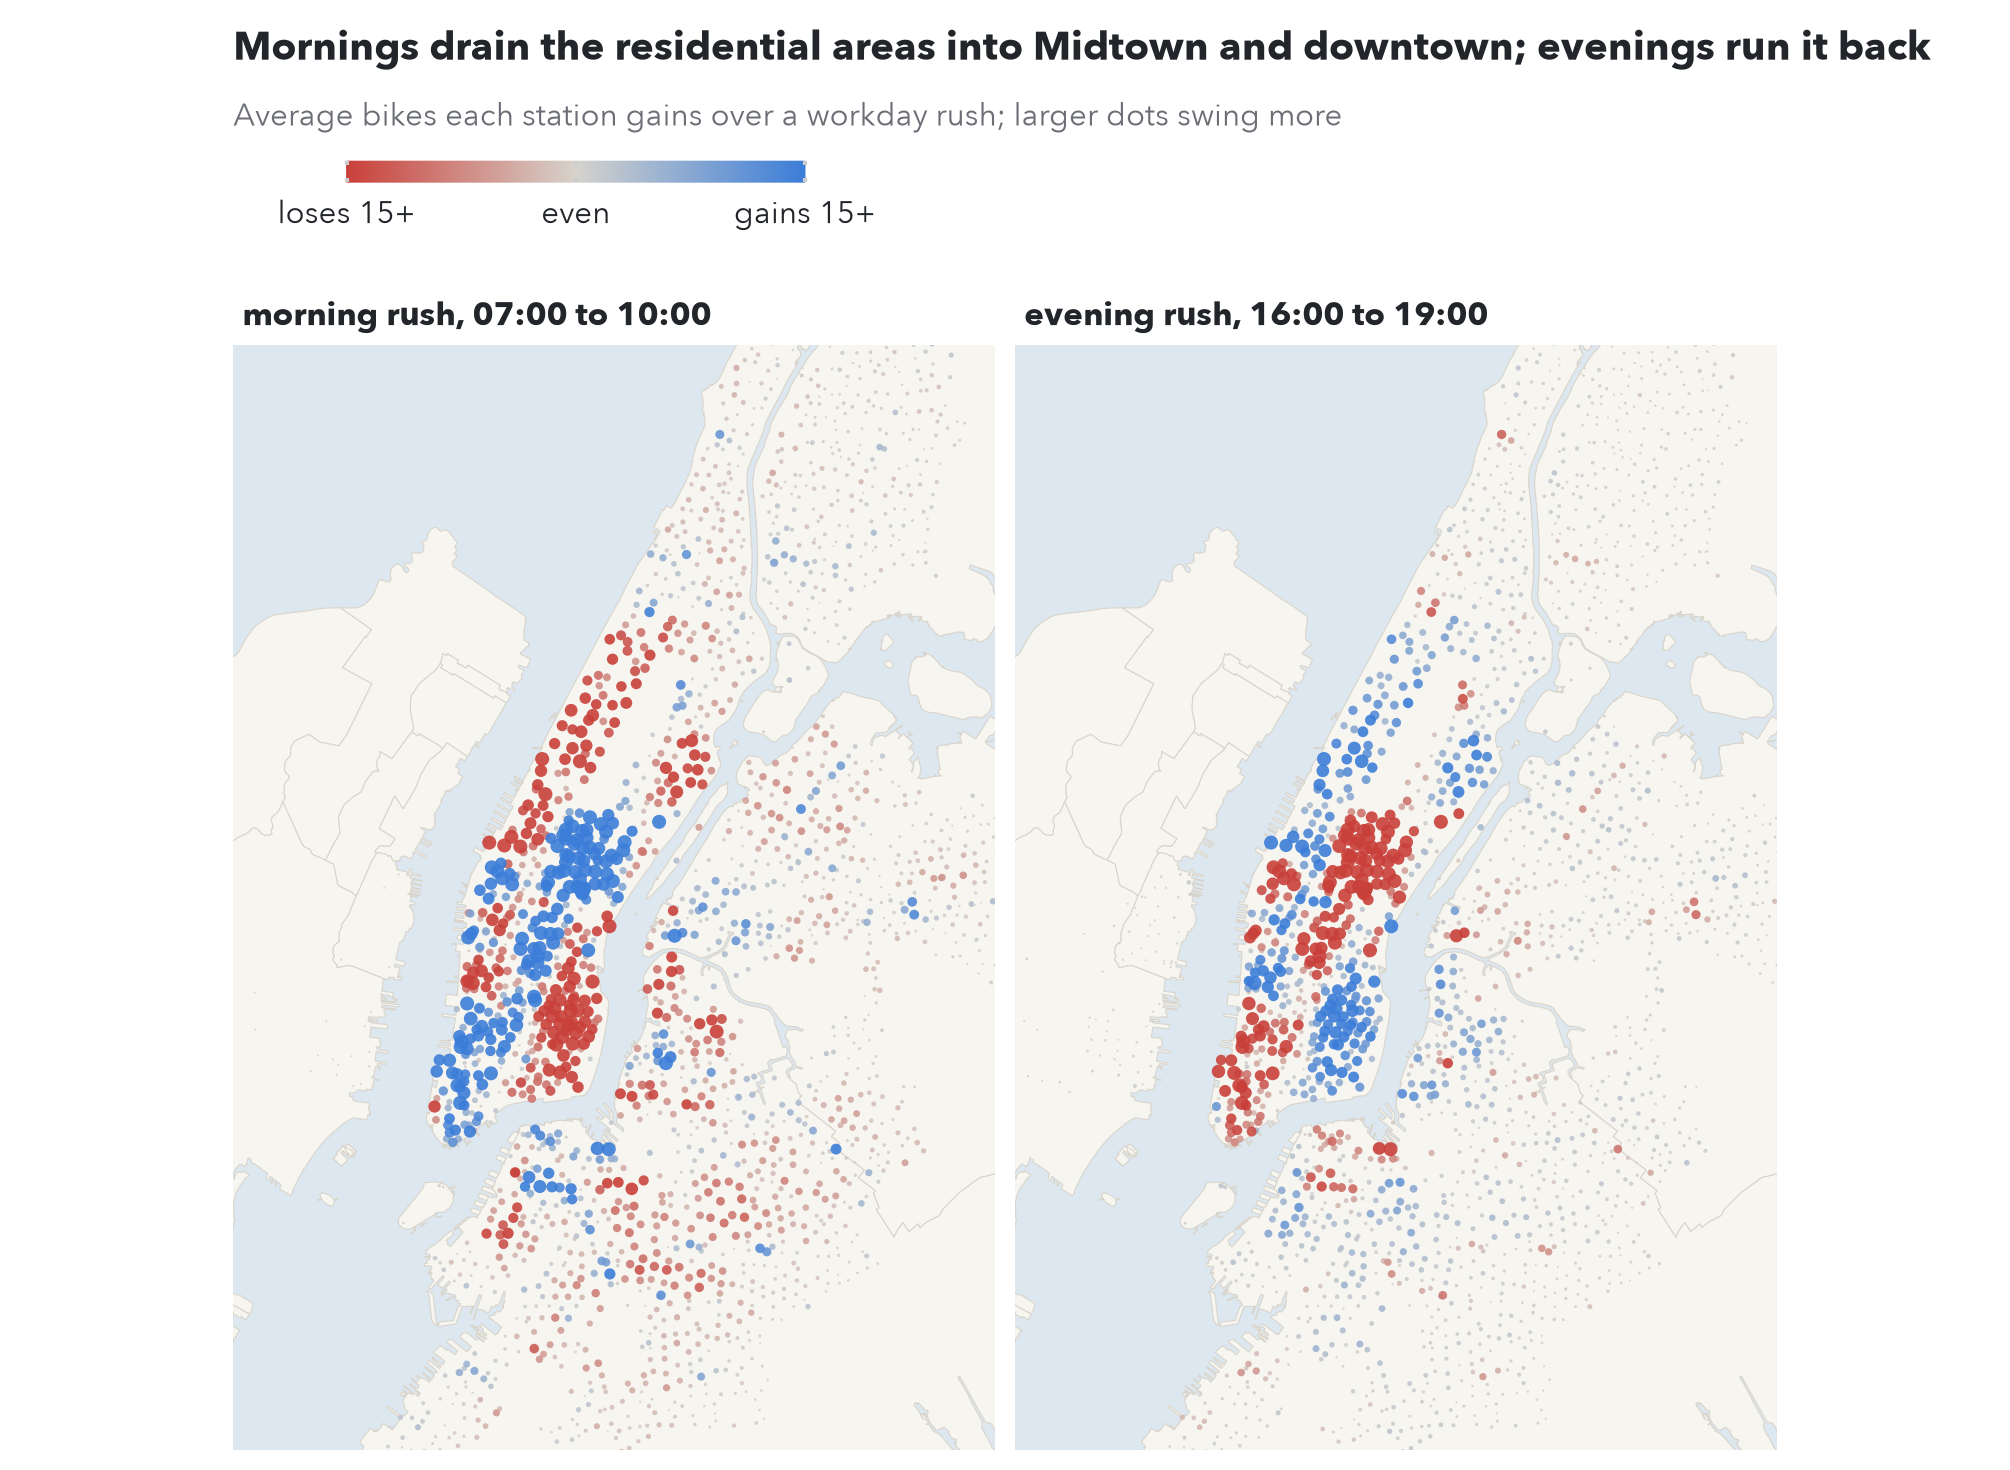

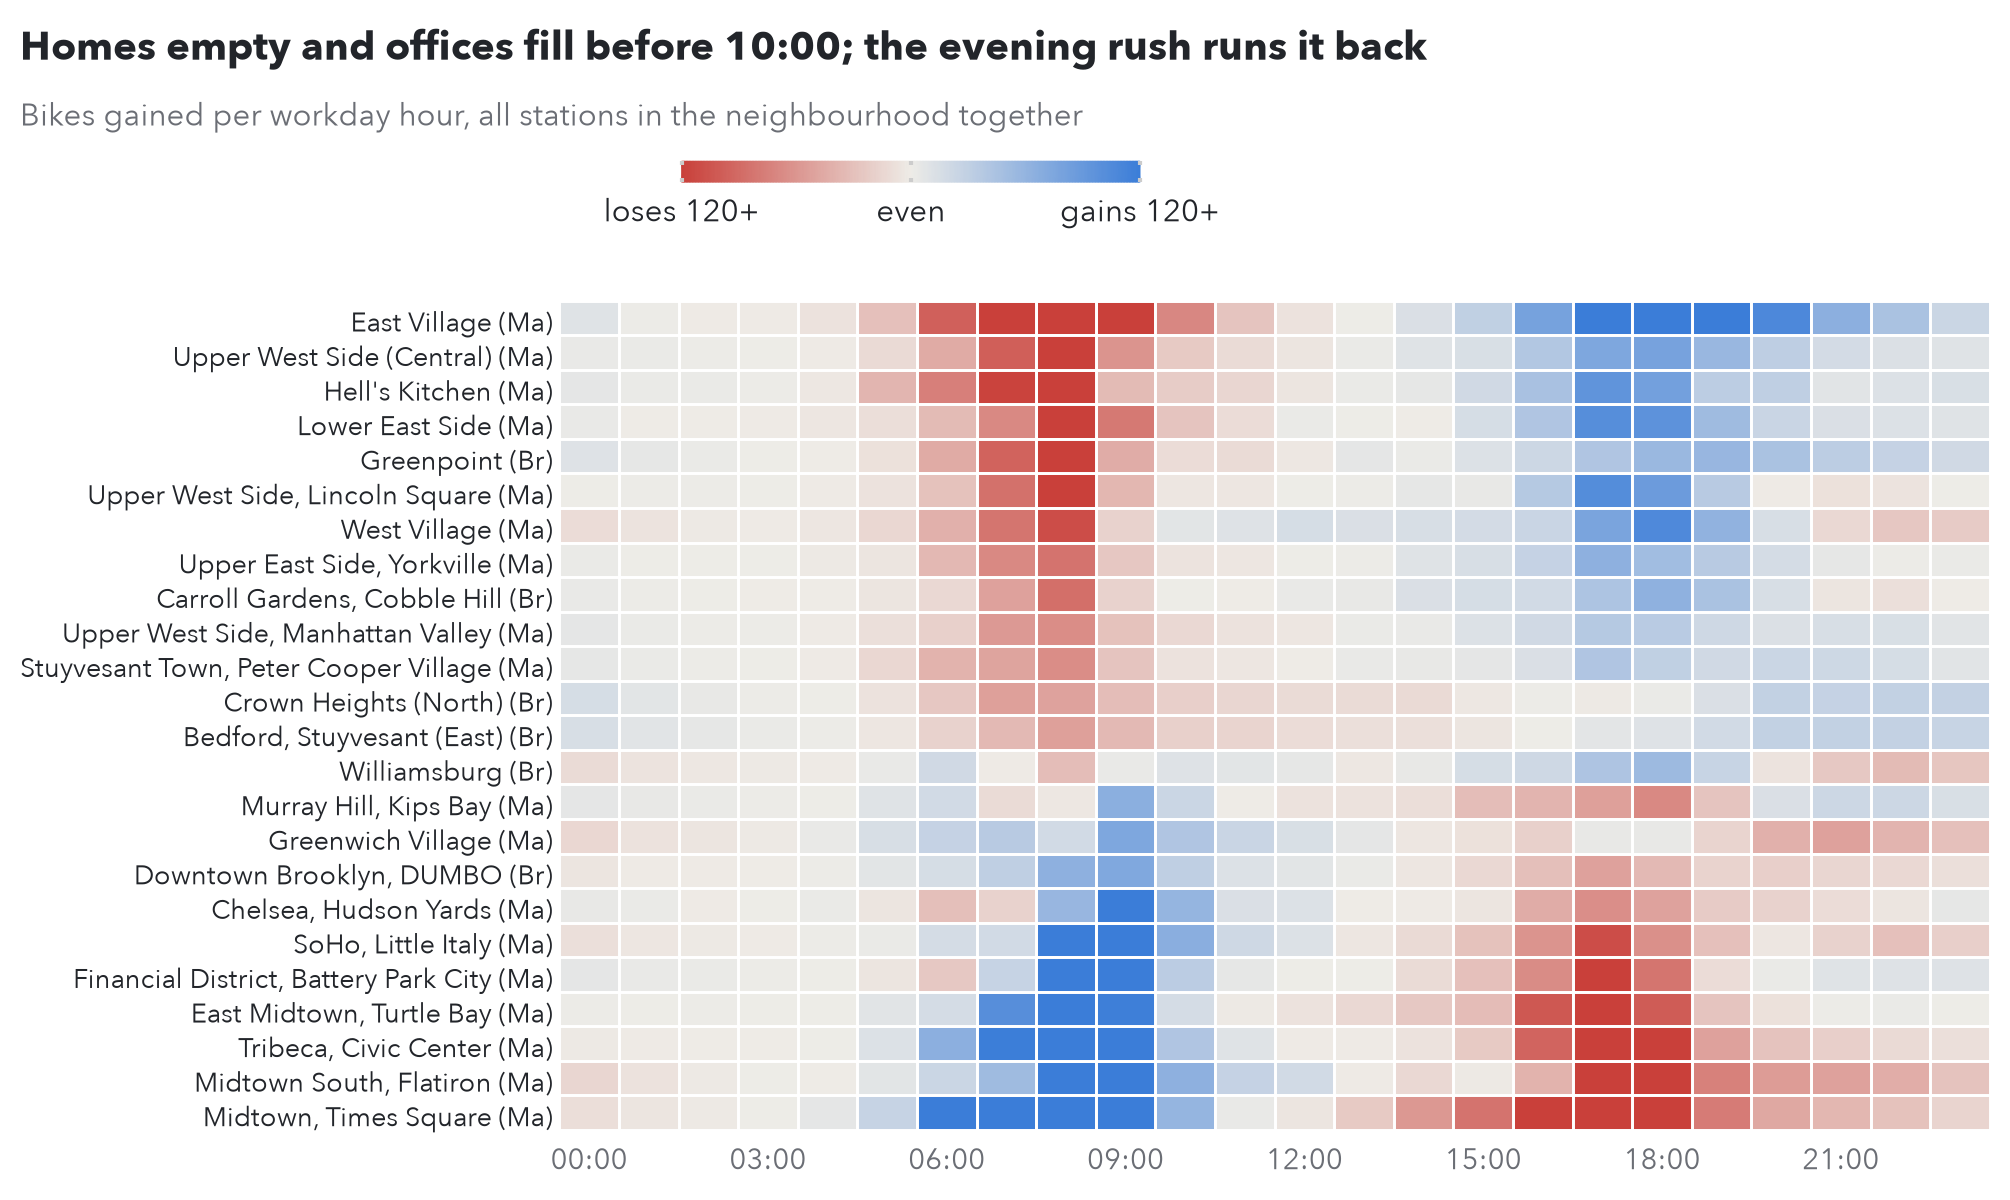

In [6]:
display(Image("figures/fig2-rush-map.png", width=800))
display(Image("figures/fig3-neighbourhood-clock.png", width=800))

Figure 2: in the morning rush Manhattan gains about 935 bikes and Brooklyn loses 1,055; the
evening reverses it. Figure 3: each neighbourhood has its own clock. Homes drain 06:00 to
10:00, offices fill then and drain 16:00 to 19:00, nightlife areas drain again after 21:00.
The sharp office drain from 16:00 is why a van visit at 14:00 can still help.

## 4. Can it be planned the night before?

A schedule set at night only works if tomorrow looks like the days before.

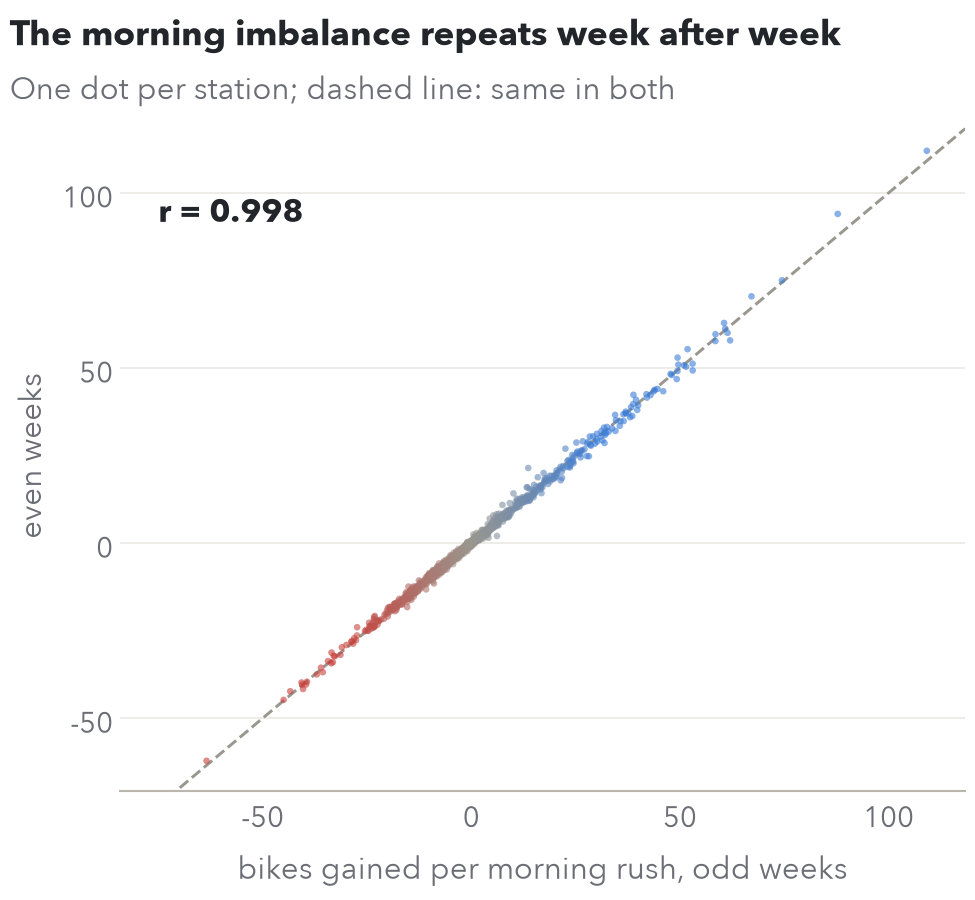

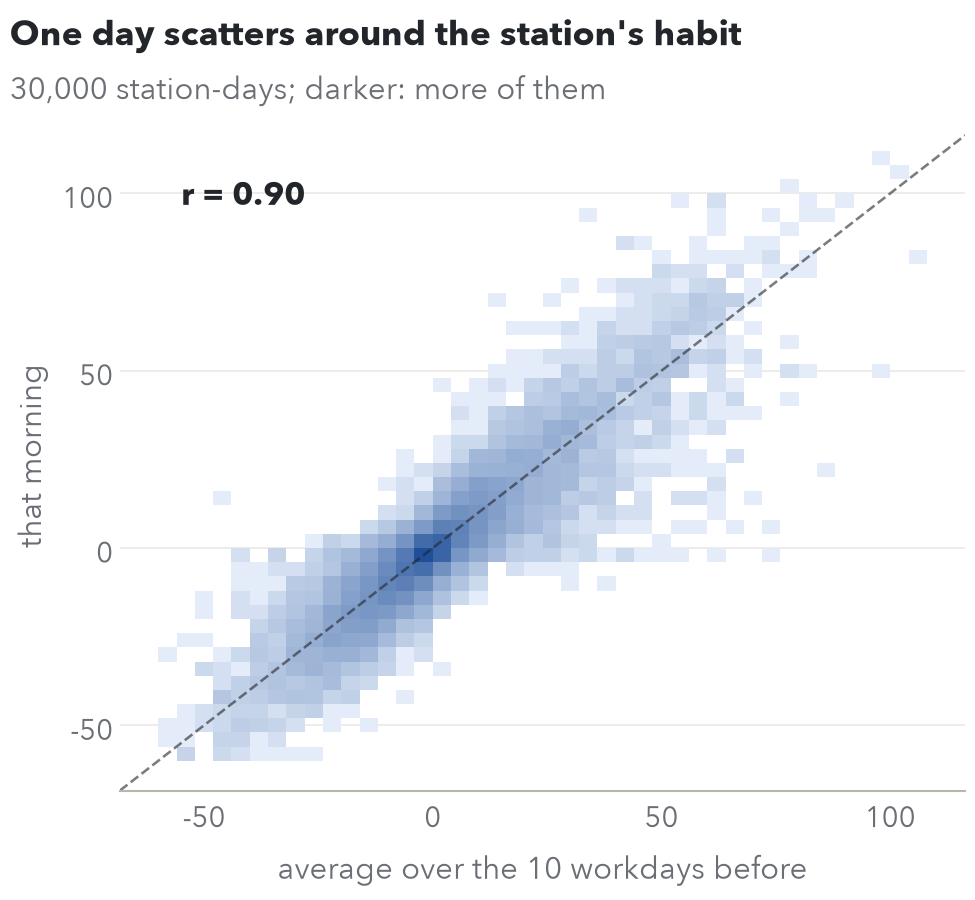

In [7]:
display(Image("figures/fig4-habit.png", width=800))
display(Image("figures/fig5-single-day.png", width=800))

On average, yes: a station's morning flow in odd weeks matches even weeks at a correlation of
0.998 (figure 4). One day is noisier: 0.90 against the average of the ten workdays before
(figure 5). So a night-before plan will be a little off at most stations.

The next check uses need and room from section 2 on every workday of the first year: how often
does a half-full start fail, and how often would no start have worked?

In [8]:
dev_workdays = (
    station_days.filter(
        pl.col("service_day").is_between(date(2024, 10, 1), date(2025, 9, 30)),
        pl.col("service_day").dt.weekday() <= 5,
        ~pl.col("service_day").is_in(HOLIDAYS),
    )
    .join(stations.select("station_id", "capacity").drop_nulls(), on="station_id")
    .with_columns(
        need=-pl.col("drift_min"),
        room=pl.col("capacity") - pl.col("drift_max"),
        half=(pl.col("capacity") / 2).round(),
    )
)
half_fails = (
    (pl.col("half") < pl.col("need")) | (pl.col("half") > pl.col("room"))
).mean()
nothing_works = (pl.col("need") > pl.col("room")).mean()
dev_workdays.select(half_fails=half_fails, nothing_works=nothing_works)

half_fails,nothing_works
f64,f64
0.21714,0.013473


A half-full start runs empty or full on about 22% of workday station-days, but on only about
1.3% would no start have worked (the swing was bigger than the docks). So nearly all the
failures come from **the wrong starting level**, and fixing the starting level is the lever.

## 5. From history to a target for each station

First, how busy will tomorrow be? A linear regression of log daily trips on weather (riding
hours 07:00 to 21:00) and calendar, fitted on the first year:

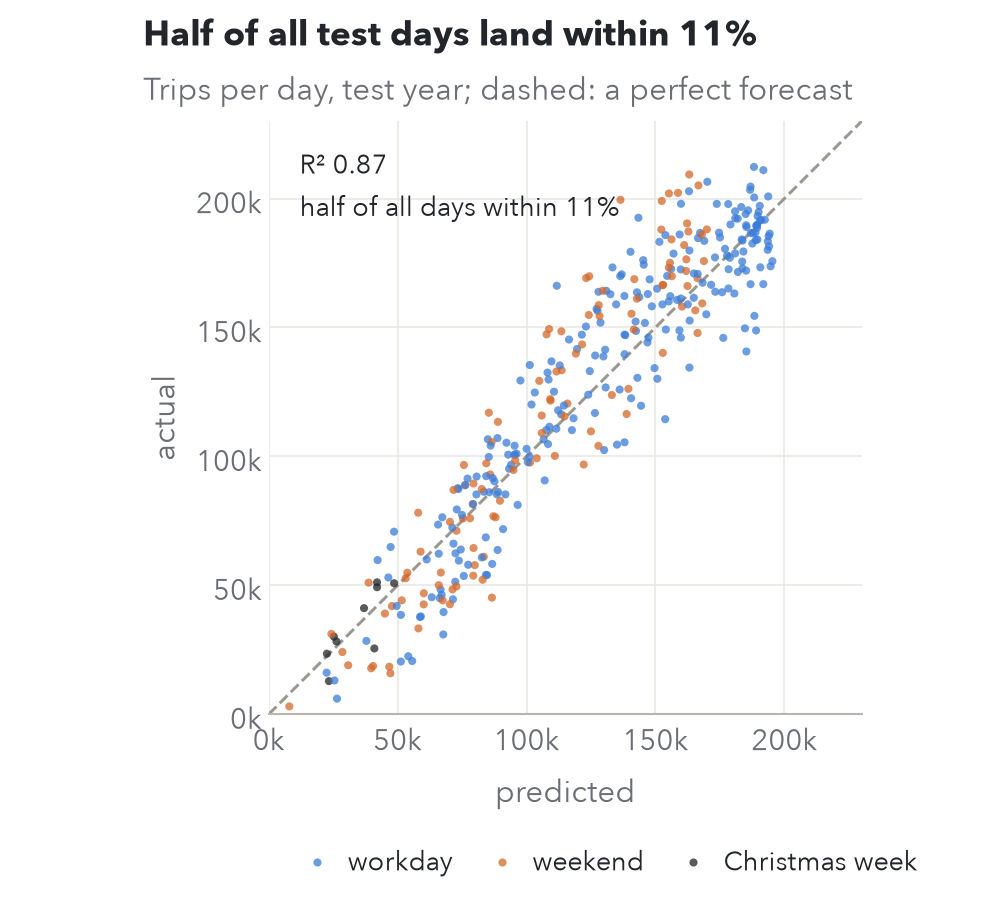

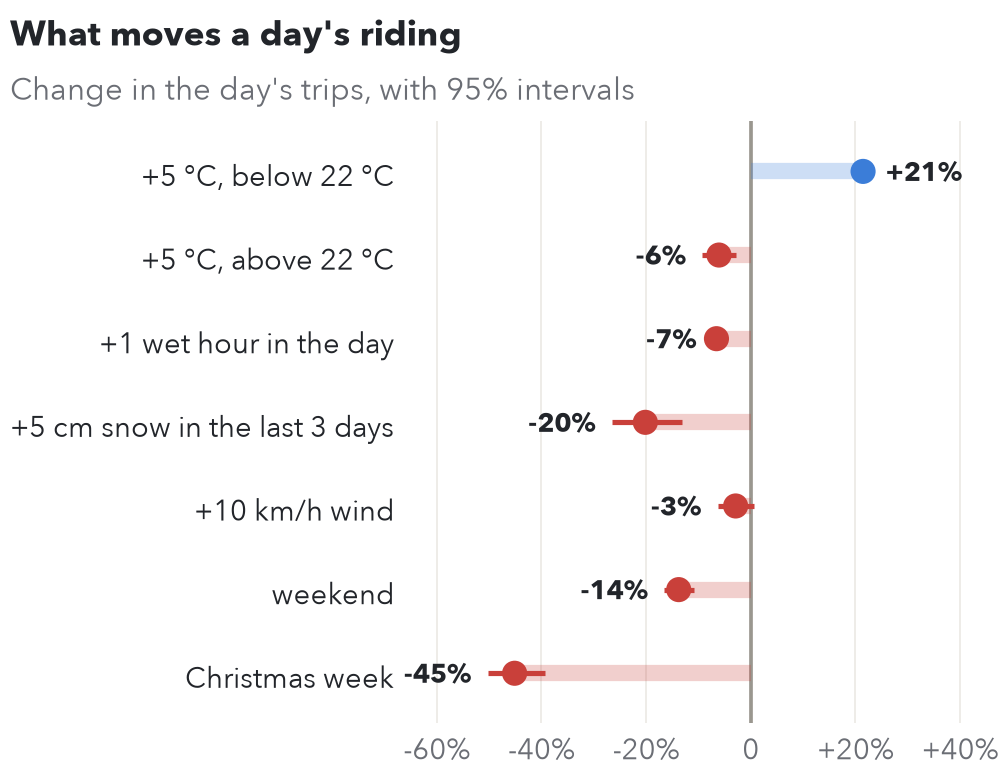

r_squared,median_miss
f64,f64
0.871156,0.11127


In [9]:
display(Image("figures/fig6-demand-model.png", width=800))
display(Image("figures/fig7-demand-effects.png", width=800))
test_days = pl.read_parquet(f"{PROCESSED}/daily_demand.parquet").filter("is_test")
test_days.select(
    r_squared=1
    - ((pl.col("trips") - pl.col("predicted")) ** 2).sum()
    / ((pl.col("trips") - pl.col("trips").mean()) ** 2).sum(),
    median_miss=(
        (pl.col("trips") - pl.col("predicted")).abs() / pl.col("trips")
    ).median(),
)

It forecasts volume well. R² is 1 minus the squared forecast errors over the squared distances
from the average day: 0.87 means the model explains 87% of how much days differ. Half of all
test days are forecast within 11%. Each wet hour costs about 6.6% of
trips, each 5 °C up to 22 °C adds about 21%. But volume does not say *where* bikes run out, and
stretching each station's history by the forecast made decisions worse (section 6). So the
station targets come from each station's own recent days.

**The target band, worked through on one station.** Take the last 10 workdays before 12 May
2026 at E 10 St & Ave A (a home station). For each day we have need and room. Starting a day
with x bikes turns away about `need - x` riders if x is below need, `x - room` if it is above
room, and none in between. Add that up over the 10 days for every x:

E 10 St & Ave A: 107 docks


service_day,need,room
date,i64,i64
2026-04-28,140,106
2026-04-29,119,107
2026-04-30,78,79
2026-05-01,69,107
2026-05-04,72,91
2026-05-05,126,106
2026-05-06,94,107
2026-05-07,82,107
2026-05-08,61,91


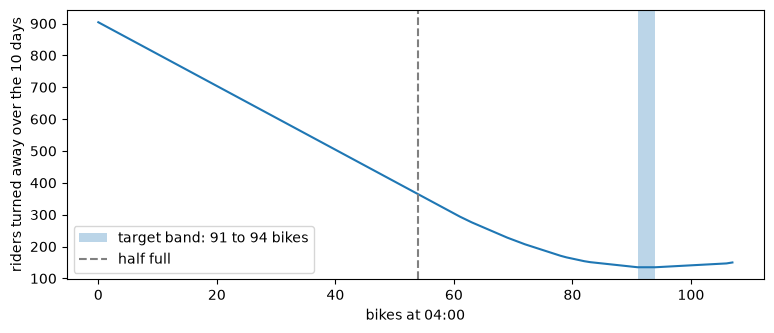

over these 10 days: half full turns away 364, the band 135


In [10]:
home = stations.filter(pl.col("name") == "E 10 St & Ave A").row(0, named=True)
last_10 = (
    station_days.filter(
        pl.col("station_id") == home["station_id"],
        pl.col("service_day") < date(2026, 5, 12),
        pl.col("service_day").dt.weekday() <= 5,
        ~pl.col("service_day").is_in(HOLIDAYS),
    )
    .sort("service_day")
    .tail(10)
    .select(
        "service_day",
        need=-pl.col("drift_min"),
        room=home["capacity"] - pl.col("drift_max"),
    )
)
print(f"{home['name']}: {home['capacity']} docks")
display(last_10)

levels = np.arange(home["capacity"] + 1)
past_need, past_room = last_10["need"].to_numpy(), last_10["room"].to_numpy()
turned_away = (
    np.maximum(past_need[None, :] - levels[:, None], 0)
    + np.maximum(levels[:, None] - past_room[None, :], 0)
).sum(axis=1)

low, high = target_band(
    past_need[None, :].astype(float), past_room[None, :].astype(float)
)
half_start = round(home["capacity"] / 2)
fig, ax = plt.subplots(figsize=(9, 3.5))
_ = ax.plot(levels, turned_away)
_ = ax.axvspan(
    low[0],
    high[0],
    alpha=0.3,
    label=f"target band: {low[0]:.0f} to {high[0]:.0f} bikes",
)
_ = ax.axvline(half_start, color="grey", ls="--", label="half full")
_ = ax.set(xlabel="bikes at 04:00", ylabel="riders turned away over the 10 days")
_ = ax.legend()
plt.show()
print(
    f"over these 10 days: half full turns away {turned_away[half_start]}, the band {turned_away[int(low[0])]}"
)

The curve is flat at its lowest, from 91 to 94 bikes: that range is the **target band**. A home
station needs to start nearly full. Half full (54) would have turned away 364 riders over these
10 days against 135 in the band, and on its worst days (need above room) no start could have
saved every rider.

Why the lowest point sits there: moving the start up one bike helps on every day where need is
still above it, and hurts on every day where room is already below it. Counting over all 20 need
and room numbers, the slope is (numbers below x) minus 10, which is zero between the 10th and
11th smallest. In other words, the band is the median of the 20 numbers. That is all
`target_band` in `lib/rebalancing.py` does.

A station already inside its band is left alone; one outside it is moved to the nearest edge.
This is the overnight-stock rule of Raviv and Kolka (2013), with the station's own last 10 days
in place of a fitted demand model.

**Settings, all chosen on the first year** before the test year was opened:

| Setting | Tried | Chosen | Why |
|---|---|---|---|
| Days of history | 5, 10, 20 | 10 | 20 days cut shortages by 1% for 10% more bikes moved |
| Stretch the band by tomorrow's forecast | yes, no | no | more shortages and more bikes moved |
| Midday visit hour | 10, 12, 14 | 14:00 | fewest shortages, just before the evening drain |
| Night budget, midday stations | 250 to 9,000; 25 to 400 | 3,000 and 100 | fewest shortages without moving more than Citi Bike reported (2,707 a day, Jan to Sep 2025) |

## 6. Simulating the schedules on the test year

**Replaying one station-day.** Back to the office station on 12 May 2026: replay its real
departures and arrivals from two starting levels and count who is turned away.
`simulate_slots` goes slot by slot: add arrivals, subtract departures, and count anything below
0 (no bike) or above the docks (no free dock) as turned away.

In [11]:
office_slots = (
    bins.filter(pl.col("station_id") == office["station_id"])
    .filter(
        pl.col("slot").is_between(
            pl.datetime(2026, 5, 12, 4), pl.datetime(2026, 5, 13, 4), closed="left"
        )
    )
    .with_columns(
        k=((pl.col("slot") - pl.datetime(2026, 5, 12, 4)).dt.total_minutes() // 5)
    )
)
starts, ends = np.zeros((1, 288), dtype=np.int16), np.zeros((1, 288), dtype=np.int16)
starts[0, office_slots["k"]] = office_slots["starts"]
ends[0, office_slots["k"]] = office_slots["ends"]

half_start = round(office["capacity"] / 2)
starting_levels = np.array([[half_start], [5]])  # [schedule, station]
_, empty, full = simulate_slots(
    starting_levels, np.array([office["capacity"]]), starts, ends
)
for name, level, no_bike, no_dock in zip(
    ["half full", "band start"],
    starting_levels[:, 0],
    empty.sum(axis=(1, 2)),
    full.sum(axis=(1, 2)),
):
    print(
        f"start {level:>3} bikes ({name}): {no_bike} found no bike, {no_dock} found no dock"
    )

start  54 bikes (half full): 0 found no bike, 50 found no dock
start   5 bikes (band start): 0 found no bike, 1 found no dock


The full simulation (`rebalance.py`) does exactly this for all 2,470 stations at once, every day
of the test year, for every schedule side by side, with one addition: a rider turned away at an
empty start station is struck from their destination's arrivals too, since that bike never
arrives. Without that, never moving a bike looks better than resetting to half full, which is
wrong.

**The schedules:**

- **No rebalancing:** stock carries over from day to day.
- **Reset to half full:** every station set to half its docks at 04:00. The benchmark.
- **Band:** every station outside its band moved to the nearest edge.
- **Night budget:** each bike moved one step toward a station's band saves some expected
  shortages, and the saving shrinks as the station nears its band. Rank every single-bike move
  across the network and take the best 3,000 (bikes loaded plus unloaded). Since each extra
  bike at a station saves less than the one before, taking the biggest savings first is the
  best possible use of the budget.
- **Budget + 14:00:** the same, plus a van visit at 14:00 to the 100 stations where it prevents
  the most shortages for the rest of the day. Recommended.
- **Band known in advance:** each station gets the best start for the day that actually
  happened. The best any overnight plan could do.

A "bike moved" is one picked up at one station and dropped at another: the larger of pickups
and drop-offs, with a depot covering the difference.

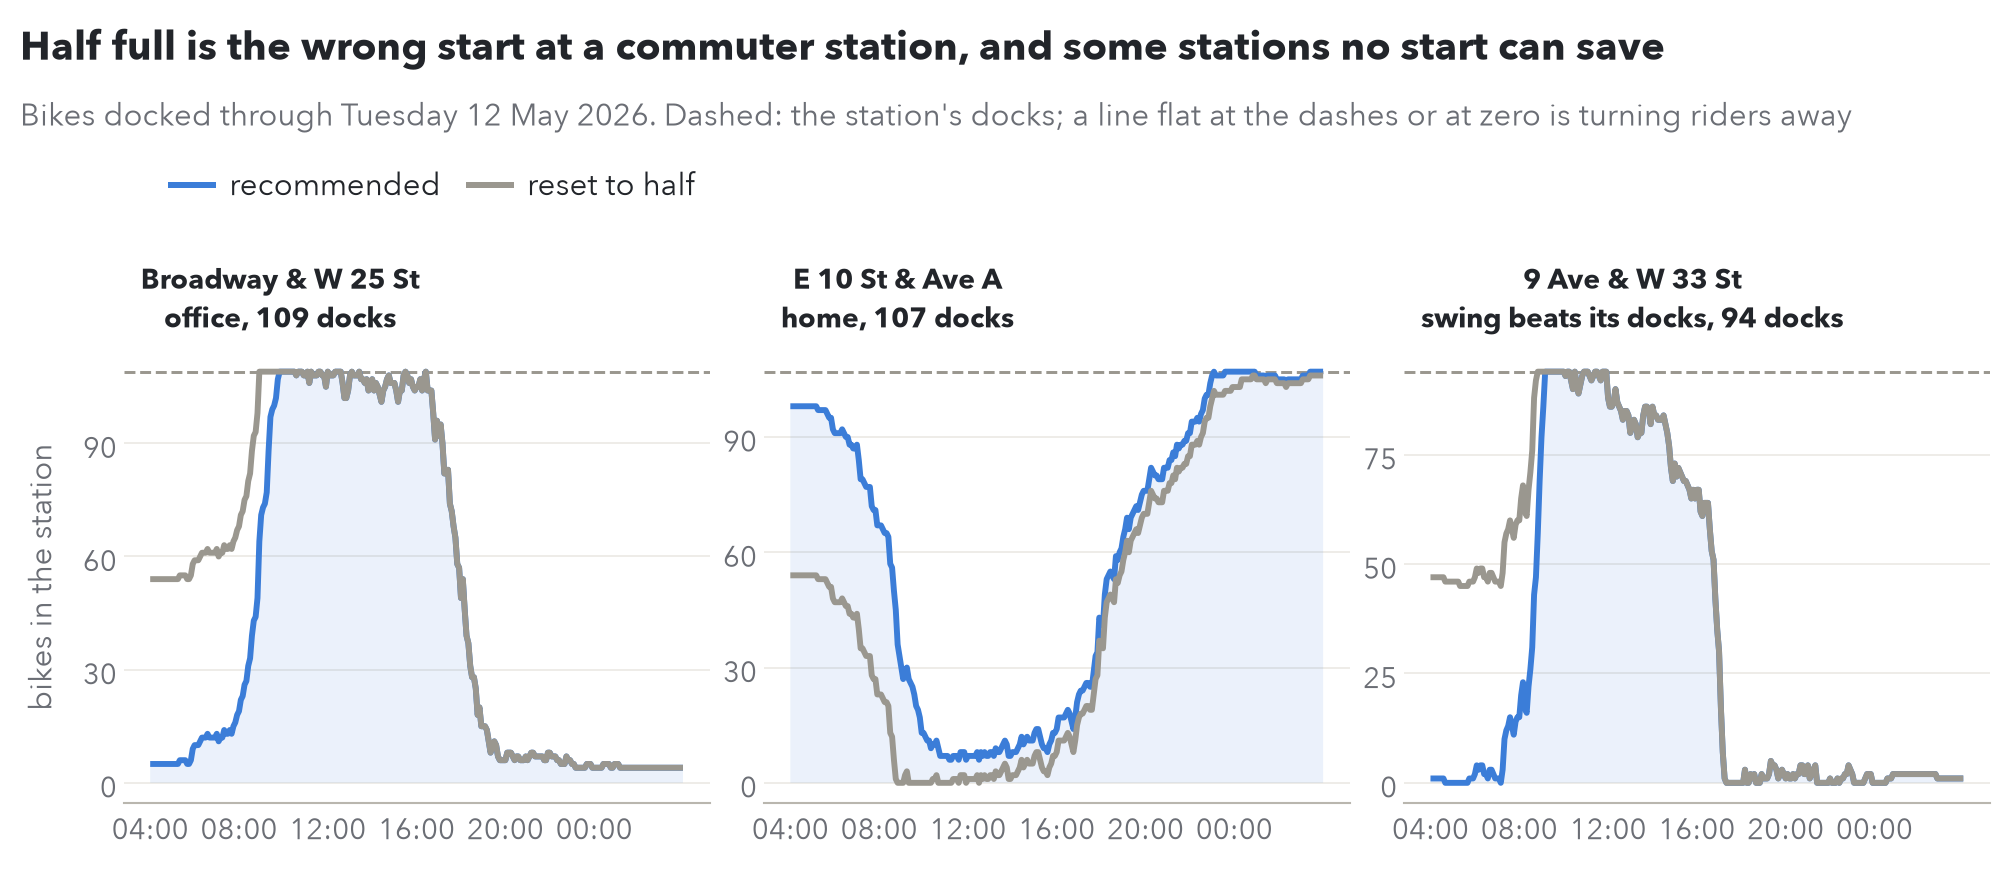

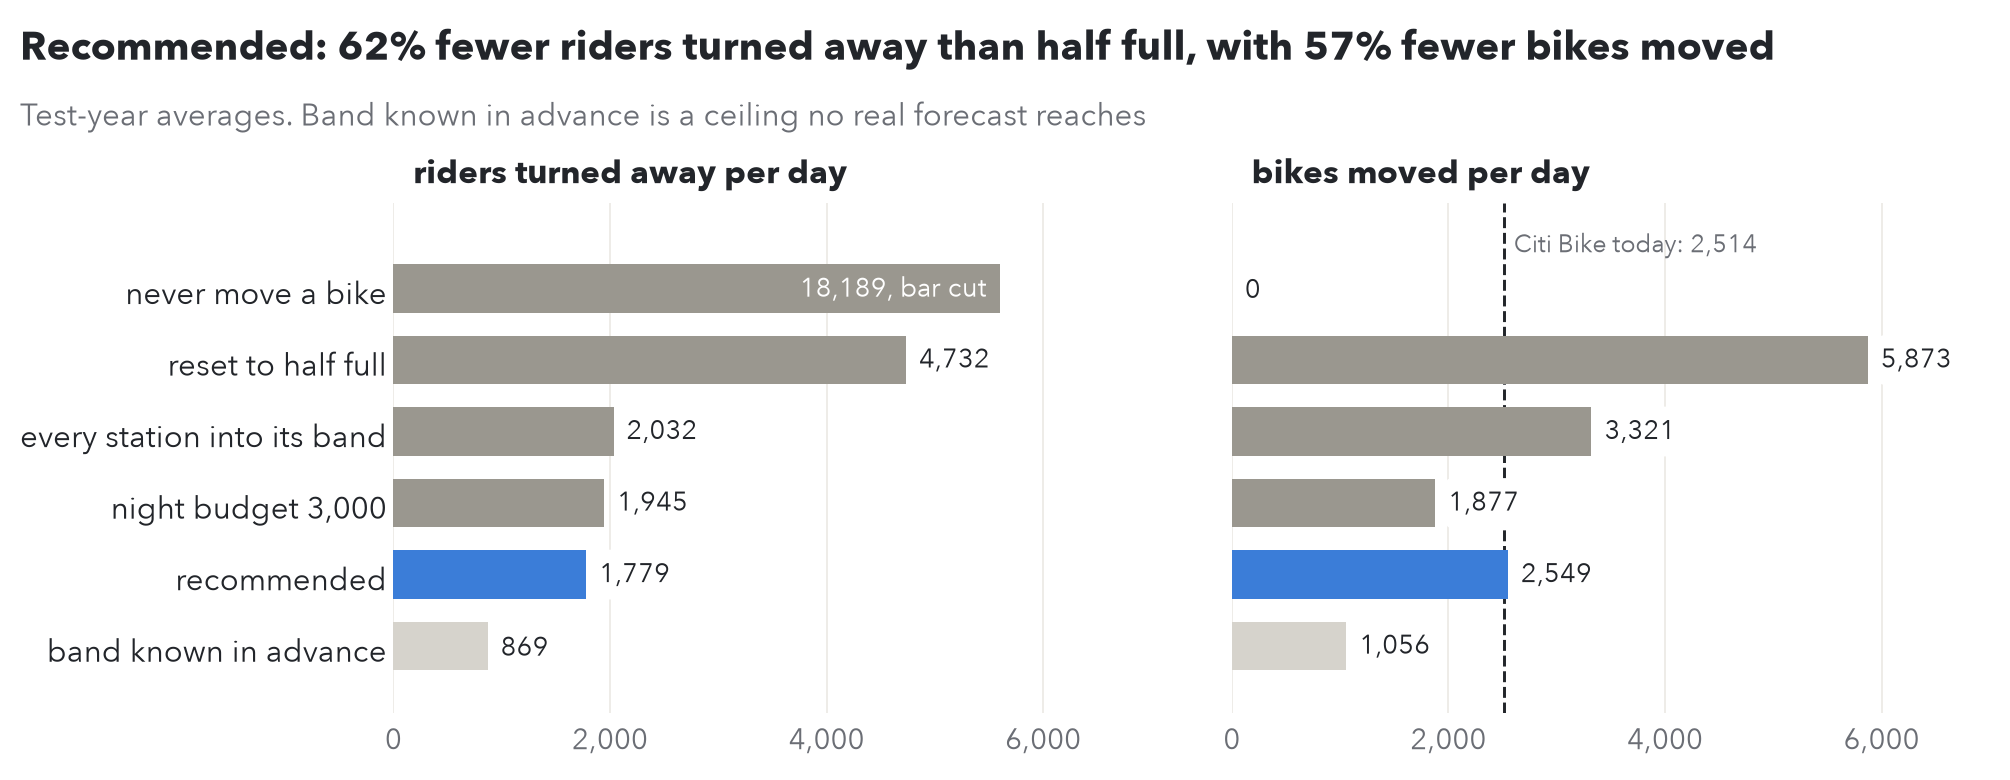

schedule,turned_away_per_day,per_100_trips,bikes_moved_per_day
str,f64,f64,f64
"""No rebalancing""",18189.0,15.0,0.0
"""Reset to half full""",4732.0,3.9,5873.0
"""Every station into its band""",2032.0,1.7,3321.0
"""Night budget of 3,000""",1945.0,1.6,1877.0
"""Budget 3,000 + 100 stations at…",1779.0,1.5,2549.0
"""Band known in advance (best ov…",869.0,0.7,1056.0


In [12]:
display(Image("figures/fig8-one-day.png", width=800))
display(Image("figures/fig9-tradeoff.png", width=800))
names = {
    "none": "No rebalancing",
    "half": "Reset to half full",
    "band": "Every station into its band",
    "budget-3000": "Night budget of 3,000",
    "budget-3000-midday-14-100": "Budget 3,000 + 100 stations at 14:00 (recommended)",
    "oracle": "Band known in advance (best overnight plan)",
}
results = (
    summary.filter(pl.col("policy").is_in(list(names)))
    .select(
        schedule=pl.col("policy").replace_strict(names),
        turned_away_per_day=pl.col("shortages_per_day").round(0),
        per_100_trips=pl.col("shortages_per_100_trips").round(1),
        bikes_moved_per_day=pl.col("bikes_moved_per_day").round(0),
    )
    .sort("turned_away_per_day", descending=True)
)
results

The headline, computed from that table:

In [13]:
by_policy = {row["policy"]: row for row in summary.iter_rows(named=True)}
half, best = by_policy["half"], by_policy["budget-3000-midday-14-100"]
fewer_shortages = 1 - best["shortages_per_day"] / half["shortages_per_day"]
fewer_bikes = 1 - best["bikes_moved_per_day"] / half["bikes_moved_per_day"]
print(
    f"recommended vs half full: {fewer_shortages:.0%} fewer riders turned away, {fewer_bikes:.0%} fewer bikes moved"
)

recommended vs half full: 62% fewer riders turned away, 57% fewer bikes moved


**What the table says**, in order of importance:

1. The half-full reset moves the most bikes and still fails: it moves bikes at stations already
   inside their band, and undoes the evening rush that had already refilled the homes.
2. A few well-aimed moves beat fixing every station: the 3,000 budget turns away 87 fewer
   riders than the band rule while moving about 1,440 fewer bikes. Past a budget of about 4,000
   it gets worse again, because the extra moves chase savings that are mostly noise.
3. The 14:00 visit is the best use of extra bikes: 166 fewer shortages for 672 more bikes,
   0.25 per bike, against 0.06 per bike for a bigger night budget.
4. Better forecasts are where the rest is: perfect knowledge of each day would reach 869.

**How sensitive is it?** Changing which rider gets the last bike when several leave a station in
the same 5 minutes (the order is not in the data) moved the recommended result from 1,779 to
1,784 a day and changed no ranking.

## 7. Where, when, and against Citi Bike's own operations

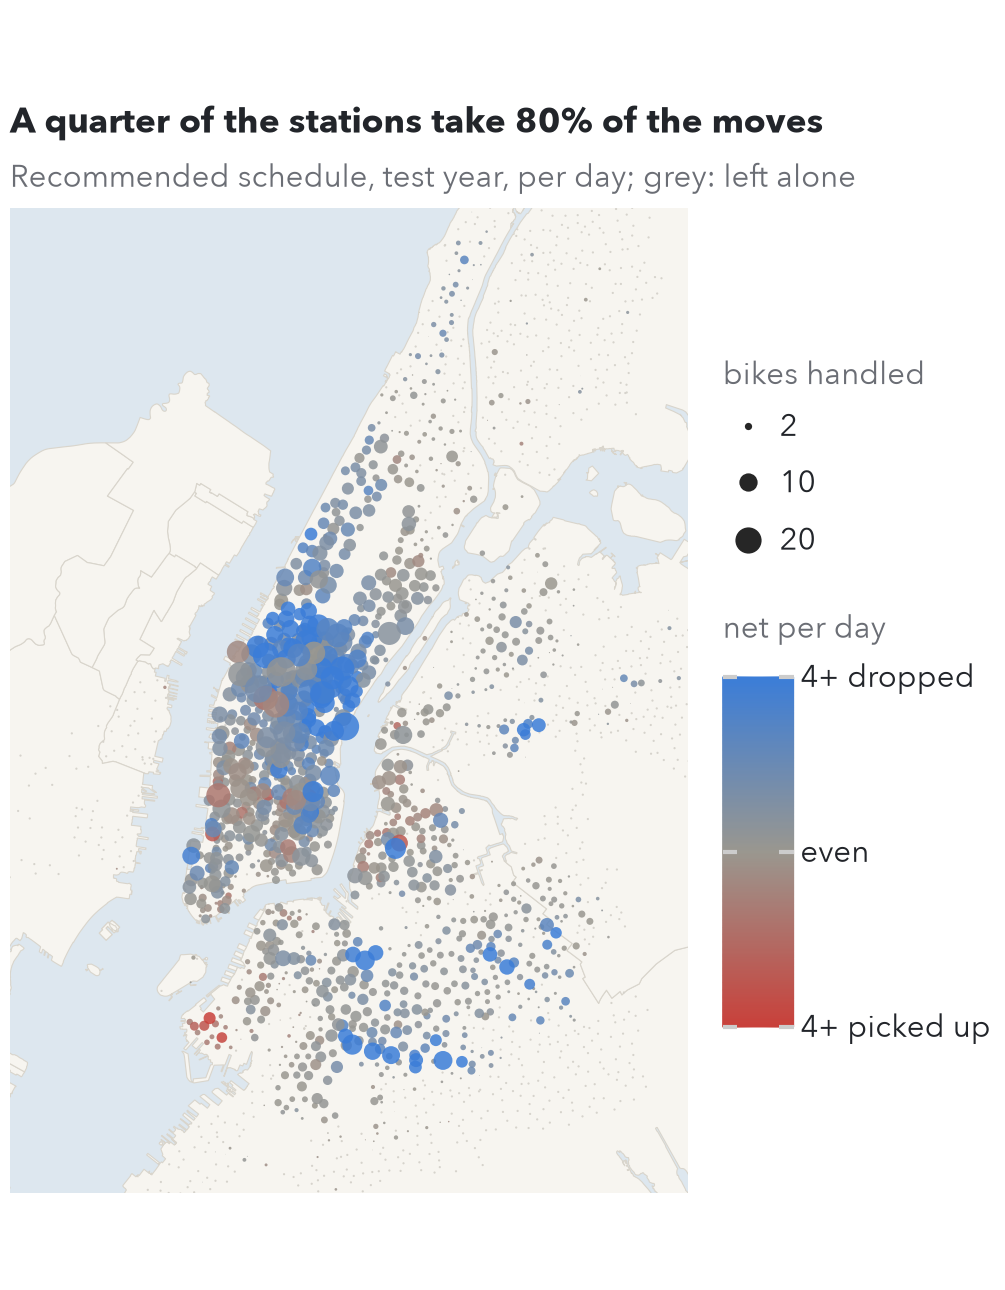

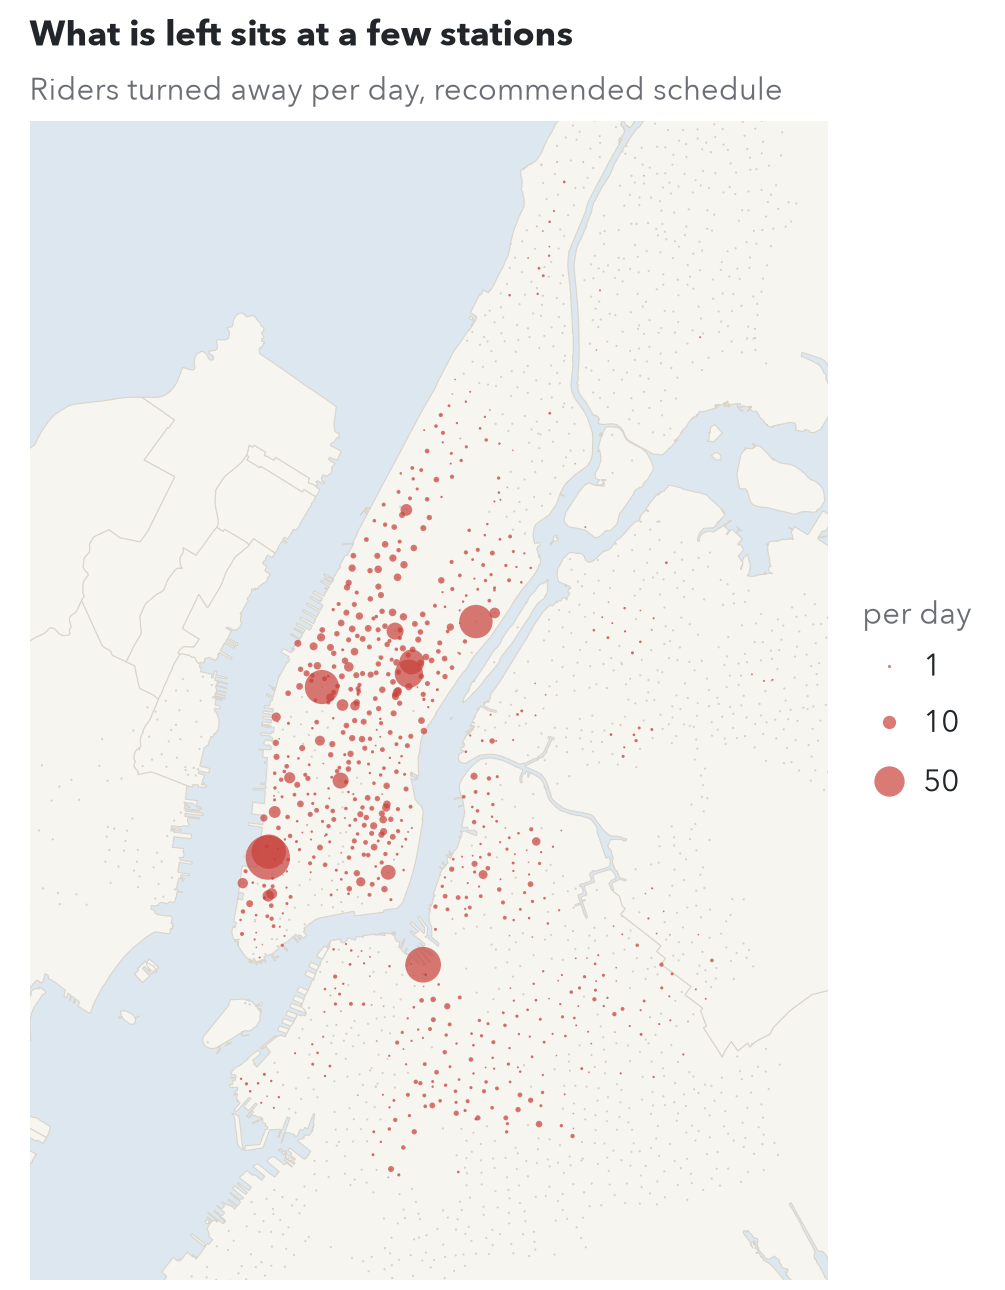

In [14]:
display(Image("figures/fig10-where-vans-go.png", width=800))
display(Image("figures/fig11-shortages-left.png", width=800))

The work is concentrated: the busiest 10% of stations take about half the bikes handled
(figure 10). What is left is even more concentrated: seven stations hold a quarter of the
remaining shortages, because their daily swing is bigger than their docks (figure 11, and the
Penn Station example in figure 8). Trucks cannot fix those; more docks or a valet can.

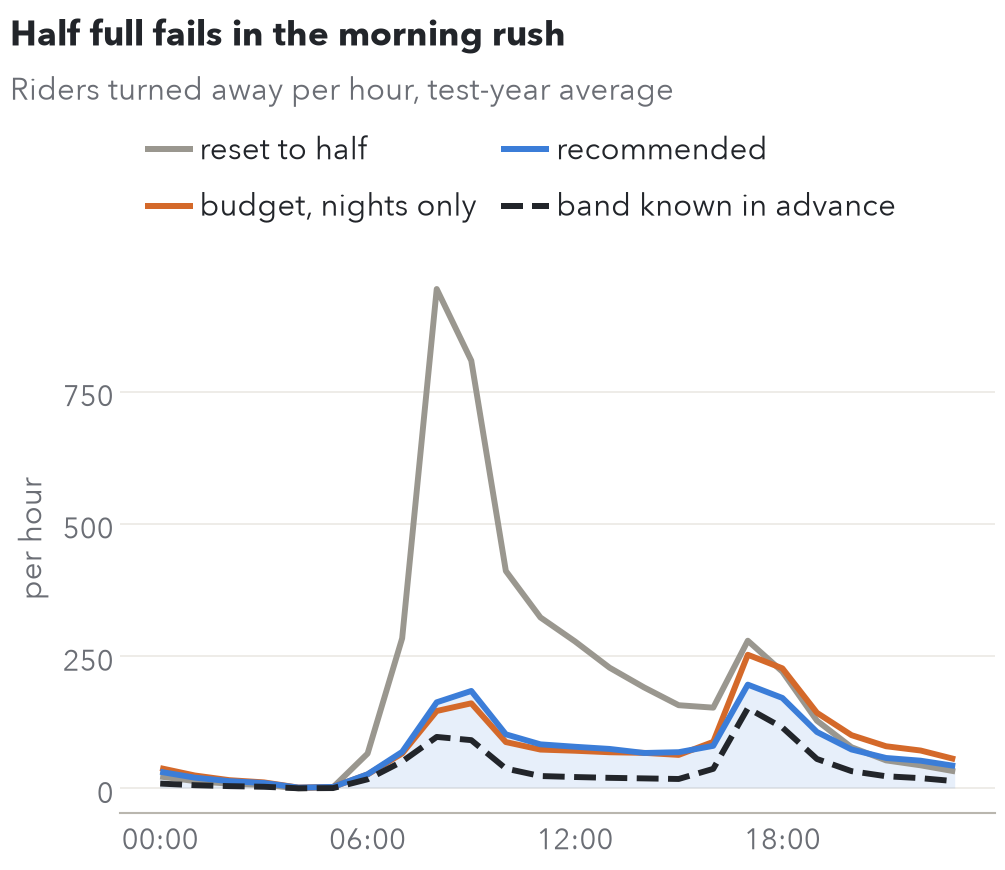

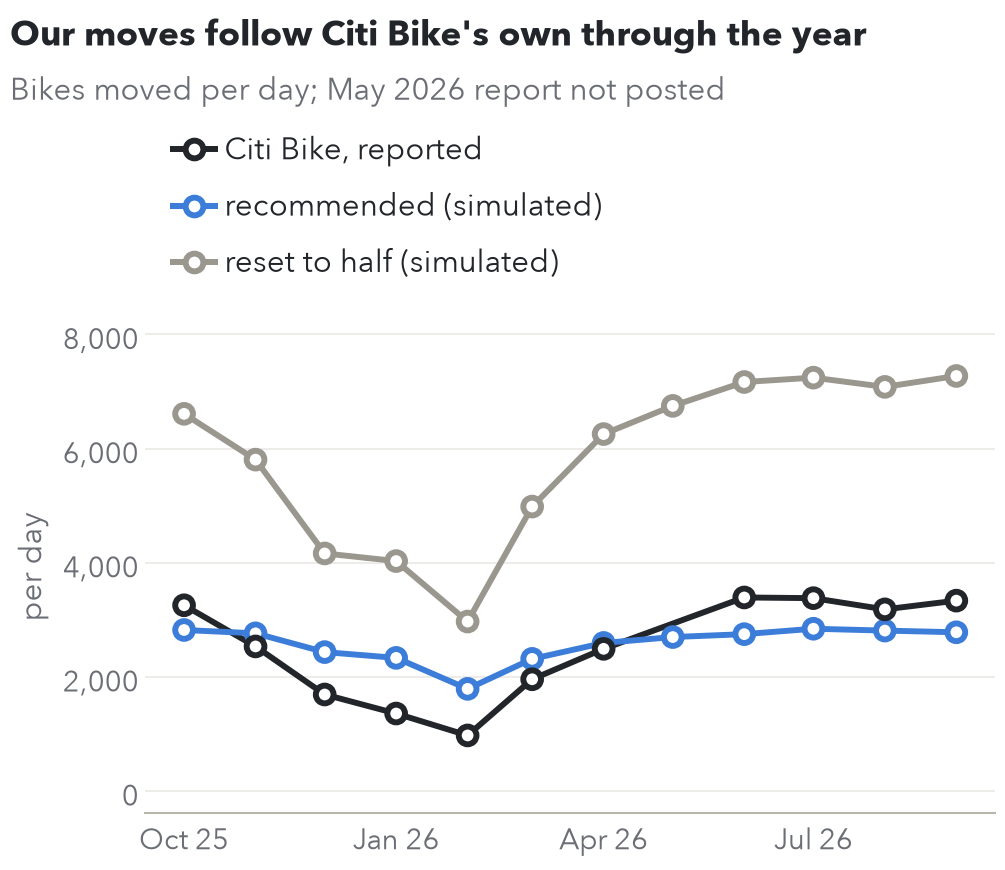

In [15]:
display(Image("figures/fig12-shortages-by-hour.png", width=800))
display(Image("figures/fig13-moves-vs-reported.png", width=800))

Figure 12: the half-full reset fails in the morning rush (wrong starting level); the
recommended schedule's worst hour is 17:00, when offices drain. Figure 13 is the reality check:
the simulated schedule moves 2,572 bikes a day in the months Citi Bike reports, against its
reported 2,514, and the two rise and fall together (correlation 0.92). Citi Bike's number also
includes Bike Angels riders and valets, so our truck workload fits inside what it already does.

## 8. Recommendations, ranked by riders saved

1. Replace the half-full reset with a target band per station, and touch only stations outside
   it (about 2,700 fewer turned away a day, 2,550 fewer bikes moved).
2. Treat the seven stations whose swing beats their docks as a capacity problem: more docks or
   valets (442 riders a day).
3. Send vans to the 100 neediest stations at 14:00 (166 fewer a day for 672 bikes).
4. Cap the night at 3,000 bikes loaded or unloaded, biggest savings first.
5. Size the night shift from the weather forecast; keep station targets on history.

## 9. Limits

Shortage counts are lower bounds. A rider at a full dock leaves the simulation instead of riding
to the next station. Docks are from one day. No routing: the cost of a move depends on how far
the van drives. No dollar figures, since no public cost per bike moved exists. And the gap to
the best overnight plan (1,779 against 869) says better station-level forecasts are worth more
than more tuning of the rule.